# Configuration

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
import os
import logging

module_path = os.path.abspath('..')
if module_path not in sys.path:
    sys.path.append(module_path)

import numpy as np
np.random.seed(42)

import pandas as pd
import pickle

import logging
import matplotlib
logging.getLogger('matplotlib').setLevel(logging.WARNING)

import matplotlib.pyplot as plt
plt.rcParams.update({
    'mathtext.fontset': 'custom',
    'mathtext.rm': 'Times New Roman',
    'mathtext.it': 'Times New Roman:italic',
    'mathtext.bf': 'Times New Roman:bold',
})

# Data import

## General

In [3]:
from ascm.preprocess.assemble import ColSelectSheet
from ascm.preprocess.misc import pickle_dump, pickle_load
from prob_settings import*
import prob_opt_settings as settings
from prob_opt_search import prepare_ds_groups

save_folder_dir_dict = settings.INP_FILE['save_folder_dir_dict']

ds_type = settings.INP_FILE['ds_type']
ds_type_suffix = settings.INP_FILE['ds_type_suffix']

# load input sheet
sh_inp_name = settings.INP_FILE['sh_inp']
sh_inp = pickle_load(save_folder_dir_dict['data'], f'{sh_inp_name}.pkl')

# load column select sheet
sh_col_select_path = os.path.join(settings.XLSX_DATA_FOLDER_DIR, settings.COLUMN_SELECT_FILE_NAME_NEW[0])
sh_col_select = ColSelectSheet(file_path=sh_col_select_path)
dict_col_sel = sh_col_select.search_colnames(
    sheet_name=ds_type+ds_type_suffix, colnames_ref_dict=settings.COLNAMES_REF_DICT)

# load data group
ds_groups_name = settings.INP_FILE['ds_groups']
ds_groups_path = os.path.join(save_folder_dir_dict['data'], f'{ds_groups_name}.pkl')
if os.path.exists(ds_groups_path):
    with open(ds_groups_path, 'rb') as f:
        ds_groups = pickle.load(f)
        logging.info(f'Read data file: {ds_groups_name}.pkl')
else:
    ds_groups = prepare_ds_groups(
        sh_inp.sheet[ds_type]['data'], 
        [settings.COLNAME_TARGET], 
        dict_col_sel)
    
    with open(ds_groups_path, 'wb') as f:
        pickle.dump(ds_groups, f)

group_key='0'
group_item = ds_groups[group_key]
id_group_i, ds_group_i = group_item

c:\Users\kangy\miniforge3\envs\cit\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Successfully loaded and processed data from 'C:\Users\kangy\OneDrive - University of Missouri\codeBench\cit\proj_scm_prob\data\initial\ASCM-col 20251008.xlsx'.
Sheets processed: ['sp_mech-us']


## Specific

In [13]:
from prob_opt_analyze_func import read_result_files, prep_data_prob_speci

os_type = 'f_c+rr'
suffix = 'bb' #! 'cr' (mortar), 'bb' (mortar), 'mp' (concrete)
suffix2 = 'nsga2' #! None, 'mopso_cd', 'nsga2'

In [14]:
from prob_opt_search import ObjOptProblem, AveragedCVRegressor_prob, ObjCallback

flag_run_prepare_data = False #!

folder_dir_01 = os.path.join(save_folder_dir_dict['data'], 'exp-01')

if flag_run_prepare_data:
    # read file path
    res_opt_paths_dict = read_result_files(
        folder_dir_01,
        file_suffix='results_optim',
        os_type_list=[suffix], #! switch ['cr', 'bb', 'mp']
        alg_type=suffix2)

    # prepare data for plotting; may take some time
    Xys_hfr_dict, convergence_metric_dict, res_opt_dict = prep_data_prob_speci(
        sh_inp,
        dict_col_sel,
        ds_group_i,
        res_opt_paths_dict,
        ds_type,
        ref_data_source='gt',
        obj_colnames=['Compressive strength', 'Replacement rate'],
        dom_colnames=['Binder 1-content', 'Binder 2-content', 'Binder 3-content', 'Binder 4-content'],
        metric_type = 'hv',
        flag_binder_content_normalize=True if suffix == 'ac' else False,
        back_up_dir='',
        save_folder_dir=folder_dir_01,
        file_name='results_optim-Xys_hist_front_ref',
        alg_type=suffix2)
else:
    Xys_hfr_dict = pickle_load(folder_dir_01, f'results_optim-Xys_hist_front_ref_{suffix}_{suffix2}_dict.pkl')
    convergence_metric_dict = pickle_load(folder_dir_01, f'results_optim-convergence_metric_{suffix}_{suffix2}_dict.pkl')
    res_opt_dict = pickle_load(folder_dir_01, f'results_optim-res_opt_{suffix}_{suffix2}_dict.pkl')
    
Xys_hist_list, Xys_front_list, Xys_ref_list = Xys_hfr_dict[suffix]
Xys_hist_df, Xys_front_df, Xys_ref_df = Xys_hist_list[0], Xys_front_list[0], Xys_ref_list[0]


# Visualization

## Mortar
suffix = 'bb'

### Domain - front

In [15]:
from prob_opt_analyze_func import convert_binder_columns

binder_phases_df = convert_binder_columns(
    Xys_front_df, 
    colnames_b_ids=['Binder 1-id', 'Binder 2-id', 'Binder 3-id', 'Binder 4-id'], 
    colnames_b_contents=['Binder 1-content', 'Binder 2-content', 'Binder 3-content', 'Binder 4-content'])
binder_phases_df[['Compressive strength', 'Compressive strength_std']] = Xys_front_df[['Compressive strength', 'Compressive strength_std']]
binder_phases_df.loc[len(binder_phases_df)] = [
    100.0, 0.0, 0.0, 0.0, 0.0, 0.0, 45.27521072, 2.308005736] # add a reference point for pure Portland cement
binder_phases_df = binder_phases_df.sort_values('Portland cement_1', ascending=False)
binder_phases_df = binder_phases_df.rename(columns=settings.BINDER_ID_PHASE_DICT)

c:\Users\kangy\OneDrive - University of Missouri\codeBench\cit\proj_scm_prob\prob_opt_analyze_func.py:266: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  phase_ids = pd.unique(phase_ids)


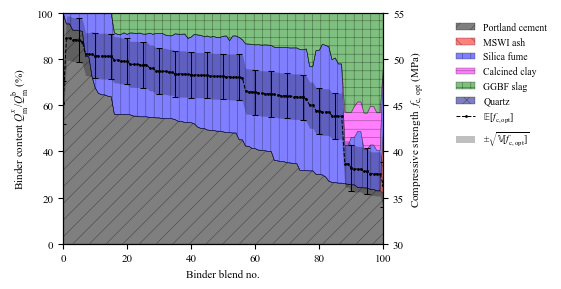

In [16]:
from ascm.vis.optimize import visualize_binder_phases_strength

STYLE_DICT = {
    'figsize': (6.0, 3.0), 
    'xlabel': 'Binder blend no.', # , ordered by decreasing Portland cement content',
    'ylabel_l': r'Binder content $Q_{\mathrm{m}}^x/Q_{\mathrm{m}}^{\mathrm{b}}$ (%)',
    'ylabel_r': r'Compressive strength $\ f_{\mathrm{c,\ opt}}$ (MPa)',
    'xaxis': [0.0, 20.0, 100.0],
    'yaxis_l': [0, 20, 100],
    'yaxis_r': [30, 5, 55],
}
visualize_binder_phases_strength(
    phases_df=binder_phases_df,
    colnames_strength=['Compressive strength', 'Compressive strength_std'],
    fig_folder_dir=save_folder_dir_dict['fig'], 
    fig_name=f'optim-front_phase_comp_{suffix}_{os_type}.png', 
    style_dict=STYLE_DICT)

### Convergence - hist

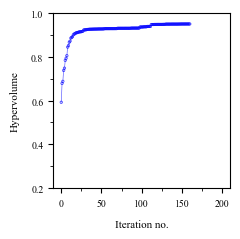

In [17]:
from prob_opt_analyze_func import plot_line_converge_metric_multi_new

for i, os_type_i in enumerate(convergence_metric_dict.keys()):
    plot_line_converge_metric_multi_new(
        convergence_metric_dict[os_type_i],
        os_type=os_type_i,
        alg_type=suffix2,
        fig_folder_dir=save_folder_dir_dict['fig'],)

### Objective & Domain - hist

In [18]:
# NOT for Domain - front - scm composition diagram

# historical data
# Map object/categorical variables to their corresponding numeric codes
for colname in settings.OPT_VARS_CATEGORY_MAP_DICT.keys():
    if colname in Xys_hist_df.columns:
        Xys_hist_df[colname] = Xys_hist_df[colname].map(settings.OPT_VARS_CATEGORY_MAP_DICT[colname])

# front data
# Map object/categorical variables to their corresponding numeric codes
for colname in settings.OPT_VARS_CATEGORY_MAP_DICT.keys():
    if colname in Xys_front_df.columns:
        Xys_front_df[colname] = Xys_front_df[colname].map(settings.OPT_VARS_CATEGORY_MAP_DICT[colname])
        

c:\Users\kangy\OneDrive - University of Missouri\codeBench\cit\ascm\vis\optimize.py:311: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


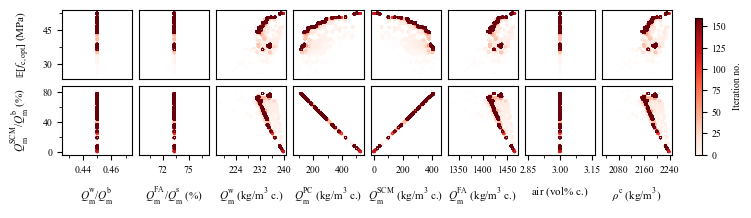

In [19]:
from ascm.vis.optimize import plot_scatter_do_hist_ref_new

dict_y_label_conv = {
    'Compressive strength': r'$\mathrm{\mathbb{E}}[f_{\mathrm{c,opt}}]$ (MPa)',
    'Replacement rate': r'$Q^{\mathrm{SCM}}_{\mathrm{m}}/Q^{\mathrm{b}}_{\mathrm{m}}$ (%)',
}

# mortar
opt_var_vis_dict = settings.OPT_VARS_VIS_DICT
colnames_dom_select_cat = 'w-b_ratio+aggregate+mixture' # 'binder', 'SCM', 'w-b_ratio+aggregate+mixture', 

plot_scatter_do_hist_ref_new(
    dom_hist_num=Xys_hist_df, obj_hist=Xys_hist_df,
    colnames_dom_select=opt_var_vis_dict[colnames_dom_select_cat], 
    colnames_obj_select=[cn for cn in dict_y_label_conv.keys() if cn in Xys_hist_df.columns],
    opt_vars_category_map_dict=settings.OPT_VARS_CATEGORY_MAP_DICT,
    dict_label_conv=DICT_PLOT_LABEL_CONV,
    dict_os_type_label_conv=settings.SPACE_SYNTHESIS_DICT_KEY_CONVERT,
    dict_y_label_conv=dict_y_label_conv,
    dom_ref_num_list=None, obj_ref_list=None,
    n_subplots_per_row=3, dim_subplots_h=0.8, dim_subplots_v=0.64,
    colname_color='Iteration',
    cmap_type='Reds',
    flag_calc_ratio=False, 
    flag_save_fig=True,
    fig_folder_dir=save_folder_dir_dict['fig'], 
    fig_name=f'optim-hist+ref_scatter-{suffix}-{os_type}-{colnames_dom_select_cat}.png')


### Objective - hist

In [20]:
dict_y_label_conv = {
    'Compressive strength': r'$\mathrm{\mathbb{E}}[f_{\mathrm{c,opt}}]$ (MPa)',
    'Replacement rate': r'$Q^{\mathrm{SCM}}_{\mathrm{m}}/Q^{\mathrm{b}}_{\mathrm{m}}$ (%)',
}
colnames_obj = [cn for cn in dict_y_label_conv.keys() if cn in Xys_hist_df.columns]+['Iteration']
o_hist  = Xys_hist_df.loc[:, colnames_obj].copy()
o_front = Xys_front_df.loc[:, colnames_obj].copy()
o_front_ideal = o_front.max(axis=0)
o_front_nadir = o_front.min(axis=0)


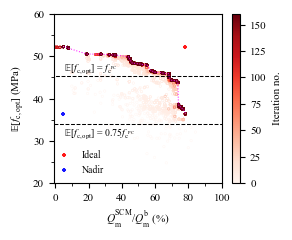

In [21]:
from ascm.vis.optimize import plot_scatter_o_hist_2d

STYLE_DICT = {
    'figsize': (3.0, 2.5), 
    'xlabel': dict_y_label_conv['Replacement rate'], # Replacement rate
    'ylabel': dict_y_label_conv['Compressive strength'], # Compressive strength
    'clabel': 'Gen no.',
    'xaxis': [-1.0, 20.0, 100.0],
    'yaxis': [20, 10, 60],
}
suffixs = f'{suffix}_{suffix2}' # os_type
plot_scatter_o_hist_2d(
    obj_hist=o_hist, 
    obj_front=o_front, 
    obj_ref=None, # o_ref_list_sel, 
    obj_front_ideal=o_front_ideal,
    obj_front_nadir=o_front_nadir, 
    obj_front_index_dm=None, obj_front_index_to=None, 
    colname_x=o_front.columns[1], 
    colname_y=o_front.columns[0], 
    colname_c=o_front.columns[-1],
    ref_horizontal=settings.THRESHOLD_STRENGTH_CONTROL,
    ref_horizontal_ratio=settings.THRESHOLD_STRENGTH_RATIO,
    cmap_type='Reds',
    fig_folder_dir=save_folder_dir_dict['fig'], 
    fig_name=f'optim-hist_scatter_2d-{suffixs}-{os_type}.svg', 
    style_dict=STYLE_DICT) # style_dict=None

## Concrete
suffix = 'mp'

### Domain - front

In [6]:
concrete_component_dict = {
    'Mixture design-binder 1':             'Portland cement', # 'Portland cement_1'
    'Mixture design-binder 2':             'GGBF slag', # 'GGBF slag_1'
    'Mixture design-binder 3':             'Silica fume', # 'silica fume_1'
    # 'Mixture design-binder 4':             '', # np.nan
    'Mixture design-water':                'Water',
    # 'Binder 1_Mixture design-binder':      'PC',
    # 'Binder 234_Mixture design-binder':    'SCM',
    'Mixture design-fine aggregate':       'Fine aggregate', # 'silica_1'
    'Mixture design-coarse aggregate':     'Coarse aggregate', # 'limestone_5'
    # 'Mixture design-targeted air content': 'Air content',
}
concrete_phases_df = Xys_front_df[list(concrete_component_dict.keys())]
concrete_phases_df[['Compressive strength', 'Compressive strength_std']] = Xys_front_df[['Compressive strength', 'Compressive strength_std']]
concrete_phases_df = concrete_phases_df.sort_values('Mixture design-binder 1', ascending=False)
concrete_phases_df = concrete_phases_df.rename(columns=concrete_component_dict)

C:\Users\kangy\AppData\Local\Temp\ipykernel_6524\2489364865.py:14: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  concrete_phases_df[['Compressive strength', 'Compressive strength_std']] = Xys_front_df[['Compressive strength', 'Compressive strength_std']]
C:\Users\kangy\AppData\Local\Temp\ipykernel_6524\2489364865.py:14: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  concrete_phases_df[['Compressive strength', 'Compressive strength_std']] = Xys_front_df[['Compressive strength', 'Compressive strength_std']]


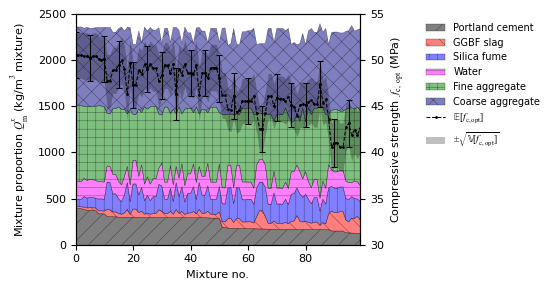

In [7]:
from ascm.vis.optimize import visualize_binder_phases_strength

STYLE_DICT = {
    'figsize': (6.0, 3.0), 
    'xlabel': 'Mixture no.', # , ordered by decreasing Portland cement content',
    'ylabel_l': r'Mixture proportion $Q_{\mathrm{m}}^x$ (kg/m$^{3}$ mixture)',
    'ylabel_r': r'Compressive strength $\ f_{\mathrm{c,\ opt}}$ (MPa)',
    'xaxis': [0.0, 20.0, 99.0],
    'yaxis_l': [0, 500.0, 2500.0],
    'yaxis_r': [30, 5, 55],
}
visualize_binder_phases_strength(
    phases_df=concrete_phases_df,
    colnames_strength=['Compressive strength', 'Compressive strength_std'],
    fig_folder_dir=save_folder_dir_dict['fig'], 
    fig_name=f'optim-front_phase_comp_{suffix}_{os_type}.png', 
    style_dict=STYLE_DICT)

### Convergence - hist

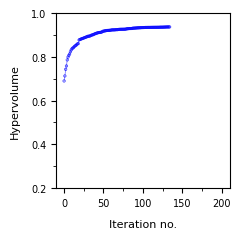

In [8]:
from prob_opt_analyze_func import plot_line_converge_metric_multi_new

for i, os_type_i in enumerate(convergence_metric_dict.keys()):
    plot_line_converge_metric_multi_new(
        convergence_metric_dict[os_type_i],
        os_type=os_type_i,
        alg_type=suffix2,
        fig_folder_dir=save_folder_dir_dict['fig'],)

### Objective & Domain - hist

In [9]:
# NOT for Domain - front - scm composition diagram

# historical data
# Map object/categorical variables to their corresponding numeric codes
for colname in settings.OPT_VARS_CATEGORY_MAP_DICT.keys():
    if colname in Xys_hist_df.columns:
        Xys_hist_df[colname] = Xys_hist_df[colname].map(settings.OPT_VARS_CATEGORY_MAP_DICT[colname])

# front data
# Map object/categorical variables to their corresponding numeric codes
for colname in settings.OPT_VARS_CATEGORY_MAP_DICT.keys():
    if colname in Xys_front_df.columns:
        Xys_front_df[colname] = Xys_front_df[colname].map(settings.OPT_VARS_CATEGORY_MAP_DICT[colname])
        

c:\Users\kangy\OneDrive - University of Missouri\codeBench\cit\ascm\vis\optimize.py:311: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


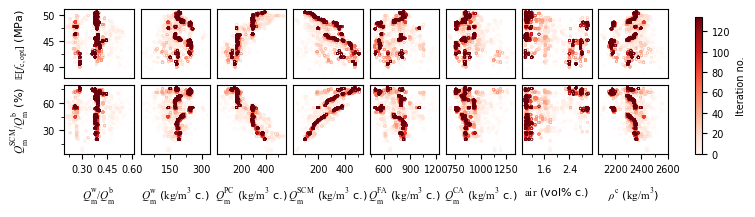

In [10]:
from ascm.vis.optimize import plot_scatter_do_hist_ref_new

dict_y_label_conv = {
    'Compressive strength': r'$\mathrm{\mathbb{E}}[f_{\mathrm{c,opt}}]$ (MPa)',
    'Replacement rate': r'$Q^{\mathrm{SCM}}_{\mathrm{m}}/Q^{\mathrm{b}}_{\mathrm{m}}$ (%)',
}

# concrete
opt_var_vis_dict = settings.OPT_VARS_VIS_CONCRETE_DICT
colnames_dom_select_cat = 'w-b_ratio+mixture' # 'binder+aggregate', 'SCM', 'w-b_ratio+mixture', 

plot_scatter_do_hist_ref_new(
    dom_hist_num=Xys_hist_df, obj_hist=Xys_hist_df,
    colnames_dom_select=opt_var_vis_dict[colnames_dom_select_cat], 
    colnames_obj_select=[cn for cn in dict_y_label_conv.keys() if cn in Xys_hist_df.columns],
    opt_vars_category_map_dict=settings.OPT_VARS_CATEGORY_MAP_DICT,
    dict_label_conv=DICT_PLOT_LABEL_CONV,
    dict_os_type_label_conv=settings.SPACE_SYNTHESIS_DICT_KEY_CONVERT,
    dict_y_label_conv=dict_y_label_conv,
    dom_ref_num_list=None, obj_ref_list=None,
    n_subplots_per_row=3, dim_subplots_h=0.8, dim_subplots_v=0.64,
    colname_color='Iteration',
    cmap_type='Reds',
    flag_calc_ratio=False, 
    flag_save_fig=True,
    fig_folder_dir=save_folder_dir_dict['fig'], 
    fig_name=f'optim-hist+ref_scatter-{suffix}-{os_type}-{colnames_dom_select_cat}.png')


### Objective - hist

In [11]:
dict_y_label_conv = {
    'Compressive strength': r'$\mathrm{\mathbb{E}}[f_{\mathrm{c,opt}}]$ (MPa)',
    'Replacement rate': r'$Q^{\mathrm{SCM}}_{\mathrm{m}}/Q^{\mathrm{b}}_{\mathrm{m}}$ (%)',
}
colnames_obj = [cn for cn in dict_y_label_conv.keys() if cn in Xys_hist_df.columns]+['Iteration']
o_hist  = Xys_hist_df.loc[:, colnames_obj].copy()
o_front = Xys_front_df.loc[:, colnames_obj].copy()
o_front_ideal = o_front.max(axis=0)
o_front_nadir = o_front.min(axis=0)


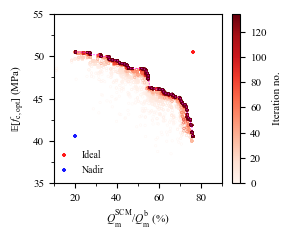

In [12]:
from ascm.vis.optimize import plot_scatter_o_hist_2d

STYLE_DICT = {
    'figsize': (3.0, 2.5), 
    'xlabel': dict_y_label_conv['Replacement rate'], # Replacement rate
    'ylabel': dict_y_label_conv['Compressive strength'], # Compressive strength
    'clabel': 'Gen no.',
    'xaxis': [10.0, 20.0, 90.0],
    'yaxis': [35, 5, 55],

}
suffixs = f'{suffix}_{suffix2}' # os_type
plot_scatter_o_hist_2d(
    obj_hist=o_hist, 
    obj_front=o_front, 
    obj_ref=None, # o_ref_list_sel, 
    obj_front_ideal=o_front_ideal,
    obj_front_nadir=o_front_nadir, 
    obj_front_index_dm=None, obj_front_index_to=None, 
    colname_x=o_front.columns[1], 
    colname_y=o_front.columns[0], 
    colname_c=o_front.columns[-1],
    ref_horizontal=None, # settings.THRESHOLD_STRENGTH_CONTROL,
    ref_horizontal_ratio=None,# settings.THRESHOLD_STRENGTH_RATIO,
    cmap_type='Reds',
    fig_folder_dir=save_folder_dir_dict['fig'], 
    fig_name=f'optim-hist_scatter_2d-{suffixs}-{os_type}.svg', 
    style_dict=STYLE_DICT) # style_dict=None